In [1]:
%reload_ext autoreload
%autoreload 2

import warnings
warnings.filterwarnings('ignore')

import pandas as pd
from functools import reduce
from copy import deepcopy

from rdkit import Chem
from rdkit.Chem import PandasTools

PandasTools.RenderImagesInAllDataFrames(images=True)
from rdkit import RDLogger; RDLogger.DisableLog('rdApp.*')

from rdkit.Chem.Draw import IPythonConsole
IPythonConsole.ipython_useSVG = True
IPythonConsole.molSize = 700, 500
# IPythonConsole.drawOptions.addAtomIndices = True

In [2]:
database3 = pd.read_csv('data/Database3.csv')
PandasTools.AddMoleculeColumnToFrame(database3, 'ISOSMILES')

# Keep only NRPs with BGCs
database3 = database3[(database3['BGC_MIBIG'].notna())]
database3 = database3.dropna(subset=['ROMol'])
database3 = database3[database3['ROMol'].apply(lambda x: x.HasSubstructMatch(Chem.MolFromSmiles('NCC(=O)')))]

df_lipidmaps = pd.read_pickle('data/Database_lipidmaps.pkl')

In [3]:
import mols2grid
mols2grid.display(database3, mol_col='ROMol', subset=['BGC_MIBIG'],
                  style={'BGC_MIBIG': lambda x: "font-weight: bold;"})

MolGridWidget()

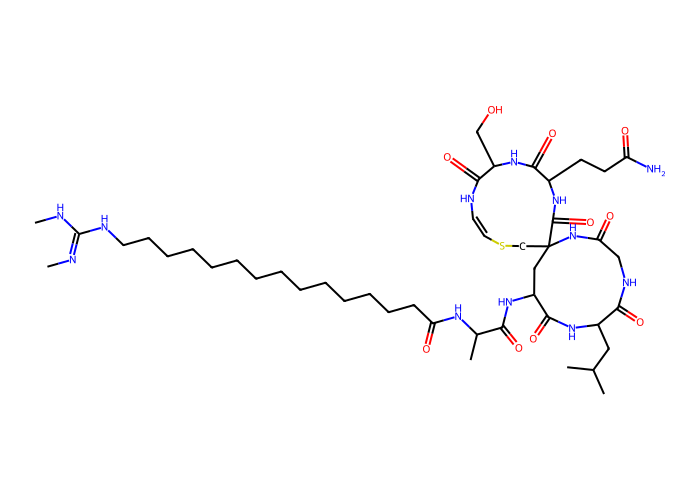

CytoscapeWidget(cytoscape_layout={'name': 'cose'}, cytoscape_style=[{'selector': 'node', 'css': {'content': 'd…

In [19]:
query_mol = database3.at[661, 'ROMol']
display(query_mol)

from new_geass import Geass
geass = Geass()
final_prods = geass.get_fragments(query_mol)
geass.show_connections_graph()

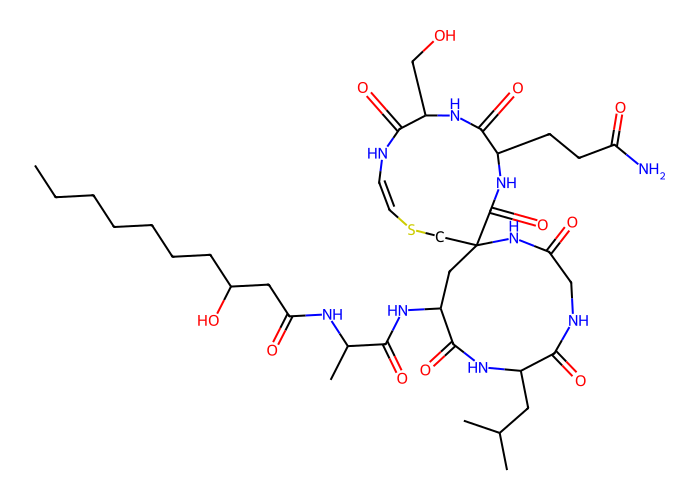

In [20]:
# Replace fatty acid tail
bu_to_replace = [x for x in final_prods if x.GetProp('BU_ID') == 'UC0002'][0]
# new_bu = df_lipidmaps[df_lipidmaps['ID'].str.contains('FA01')]['ISOSMILES'].values[858]
new_bu = 'CCCCCCCC(O)CC(=O)O'
chimera = geass.replace_BUs(query_mol, bu_to_replace, Chem.MolFromSmiles(new_bu), 'fas')
chimera

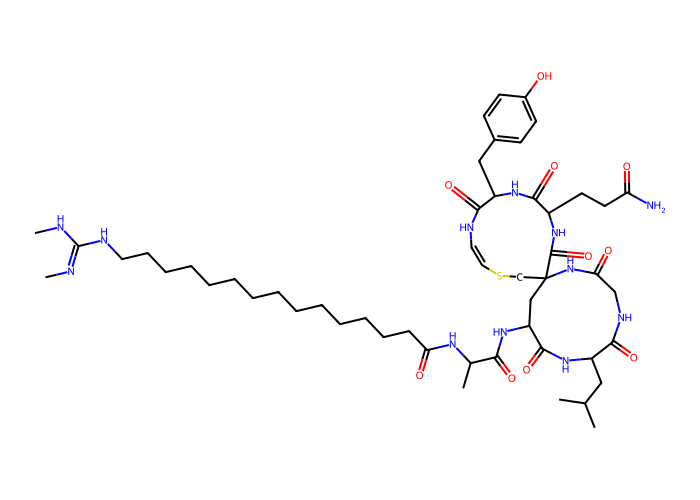

In [22]:
# Replace an amino acid
bu_to_replace = [x for x in final_prods if x.GetProp('BU_ID') == 'C00065'][0]
new_bu = Chem.MolFromSmiles('C1=CC(=CC=C1CC(C(=O)O)N)O')
chimera = geass.replace_BUs(query_mol, bu_to_replace, new_bu, 'aas')
chimera